In [1]:
import os
import sys

# Assuming your dataset module is at the same level as the current script
dataset_path = os.path.abspath(os.path.join(os.getcwd(), '..', 'CL_COREF'))
sys.path.append(dataset_path)

from dataset import CDCR_Dataset
sys.path.remove(dataset_path)

c:\ProgramData\miniconda3\envs\dnlp\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import pandas as pd
import spacy
import nltk
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
sp = spacy.load('en_core_web_sm')
spacy_stopwords = sp.Defaults.stop_words
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\sago\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [4]:
with open('dapt_political_cognitive_bias.txt','r') as file:
    lines = file.readlines()

In [6]:
sizes = [len(x) for x in lines]

In [13]:
sizes.pop(135803)

29384

<Axes: ylabel='Count'>

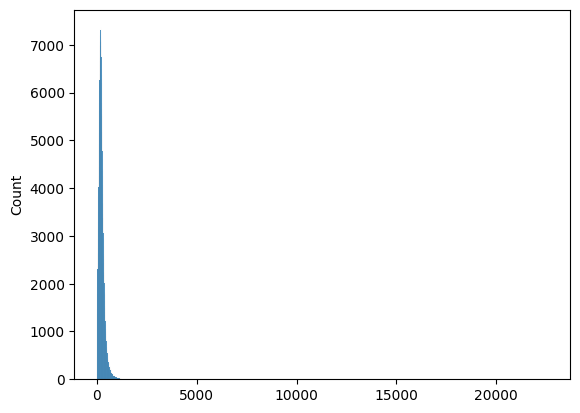

In [14]:
sns.histplot(sizes)

In [12]:
lines[135803]

'Sadly Kristof s assessment can be applied elsewhere around the world It seems that President Obama and the administration as a whole have struggled to find its voice when it comes to the promotion and protection of basic human rights and religious freedom These most cherished ideals which are at the very heart of the American experiment have time and again been sidelined in this administration s foreign policy This is a grievous mistake which has dire implications for the world s dissidents and democrats who yearn for freedom and look to America to be their advocate Looking back to Sudan a nation I first visited in 1989 and most recently in 2004 when Senator Sam Brownback and I were the first congressional delegation to go to Darfur I remain deeply concerned that the country is headed for a resumption of civil war if the U S fails to exert the necessary leadership While there were certainly times that I was critical of the Bush Administration s policies it is indisputable that he and 

In [ ]:
lines.pop

In [10]:
sizes.index(29384)

135803

In [9]:
max(sizes)

29384

In [5]:
def sentences_dict_to_list(sentences_dict):
    sentences_list = []
    for doct_dict in sentences_dict.values():
        for mini_dict in doct_dict.values():
            sentences_list.append(' '.join(mini_dict.values()))
    
    return sentences_list

In [6]:
#Load ECB+ val and no val
ecb_paths = ['../CDCR/data/ECBplus-prep/output_data/train',
            '../CDCR/data/ECBplus-prep/output_data/val',
             '../CDCR/data/ECBplus-prep/output_data/test']
ecb_train = CDCR_Dataset(name="ecbplus_train", data_path=ecb_paths[0],context_method="hsu")
ecb_no_train = CDCR_Dataset(name="ecbplus_no_train", data_path=ecb_paths[1:],context_method="hsu")

In [7]:
ecbplus_sentences = sentences_dict_to_list(ecb_train.sentences) + sentences_dict_to_list(ecb_no_train.sentences)
ecbplus_sentences = set(ecbplus_sentences)

In [8]:
#Load ECB+ val and no val
newswcl50_paths = ['../CDCR/data/NewsWCL50-prep/output_data/train',
            '../CDCR/data/NewsWCL50-prep/output_data/val',
             '../CDCR/data/NewsWCL50-prep/output_data/test']
newswcl50 = CDCR_Dataset(name="newswcl50", data_path=newswcl50_paths,context_method="hsu")
newswcl50_sentences = set(sentences_dict_to_list(newswcl50.sentences))


In [9]:
# Function to get top tokens

def get_top_tokens(sentences_list, min_df=3, num_tokens=10000):
    # Handle NaN values by converting them to an empty string
    sentences_list = [str(sent) for sent in sentences_list if pd.notna(sent)]
    
    # Join the sentences and tokenize
    tokens = nltk.word_tokenize(" ".join(sentences_list))

    text_without_stopword = [word for word in tokens if word.lower() not in spacy_stopwords]

    # Create a frequency distribution of the tokens
    freq_dist = nltk.FreqDist(text_without_stopword)

    # Filter out tokens with frequency below min_df
    filtered_tokens = [token for token, freq in freq_dist.items() if freq >= min_df]

    # Retrieve the top N most frequent tokens
    top_tokens = freq_dist.most_common(num_tokens)

    # Extract just the tokens (without frequencies)
    top_tokens_only = set([token[0] for token in top_tokens])

    return top_tokens_only


In [10]:
top_10000_ecbplus = get_top_tokens(ecbplus_sentences)
top_10000_newswcl50 = get_top_tokens(newswcl50_sentences)

In [11]:
def jaccard_similarity(set1, set2):
    intersection_size = len(set1.intersection(set2))
    union_size = len(set1.union(set2))
    
    if union_size == 0:
        return 0  # Avoid division by zero
    
    similarity = intersection_size / union_size
    return similarity

In [12]:
jaccard_similarity(top_10000_ecbplus,top_10000_newswcl50)

0.2514333194848359

In [13]:
# Specify the directory containing the CSV files
directory_path = 'MBIB_datasets'

# List of CSV files
csv_files = [
    "cognitive-bias.csv",
    "fake-news.csv",
    "gender-bias.csv",
    "hate-speech.csv",
    "linguistic-bias.csv",
    "political-bias.csv",
    "racial-bias.csv",
    "text-level-bias.csv"
]

# Create an empty dictionary to store DataFrames
dataframes_dict = {}

# Load each CSV file into a DataFrame and store in the dictionary
for file_name in csv_files:
    file_path = os.path.join(directory_path, file_name)
    df = pd.read_csv(file_path)
    # Remove file extension to use as the dictionary key
    key = os.path.splitext(file_name)[0]
    dataframes_dict[key] = df

# Now dataframes_dict contains all DataFrames with keys as file names (without extension)


In [14]:
for k,v in dataframes_dict.items():
    print(k,len(v))
    print(v["id"].str.split("-").str[0].value_counts())

cognitive-bias 487202
id
066    474752
072     12450
Name: count, dtype: int64
fake-news 13380
id
072    7254
025    3902
012    2224
Name: count, dtype: int64
gender-bias 40092
id
105    14596
107    13017
075    11360
106     1119
Name: count, dtype: int64
hate-speech 348518
id
040    328073
092      7271
075      7024
087      6150
Name: count, dtype: int64
linguistic-bias 405288
id
026    339009
035     34570
003     11730
075     10840
049      3498
010      3480
009      1440
038       721
Name: count, dtype: int64
political-bias 501688
id
066    480492
029     17534
049      3662
Name: count, dtype: int64
racial-bias 9788
id
075    9335
110     453
Name: count, dtype: int64
text-level-bias 9018
id
076    8597
019     421
Name: count, dtype: int64


In [15]:
# Create a new dictionary for processed DataFrames using get_top_tokens function
processed_dataframes_dict = {}

# Process each DataFrame and store the result in the new dictionary
for key, df in dataframes_dict.items():
    sentences_list = df['text'].tolist()
    top_tokens = get_top_tokens(sentences_list)
    processed_dataframes_dict[key] = top_tokens

processed_dataframes_dict["ECBplus"] = set(top_10000_ecbplus)
processed_dataframes_dict["NewsWCL50"] = set(top_10000_newswcl50)

# processed_dataframes_dict.pop('fake-news',None)
# processed_dataframes_dict.pop('racial-bias',None)

In [16]:
processed_dataframes_dict.keys()

dict_keys(['cognitive-bias', 'fake-news', 'gender-bias', 'hate-speech', 'linguistic-bias', 'political-bias', 'racial-bias', 'text-level-bias', 'ECBplus', 'NewsWCL50'])

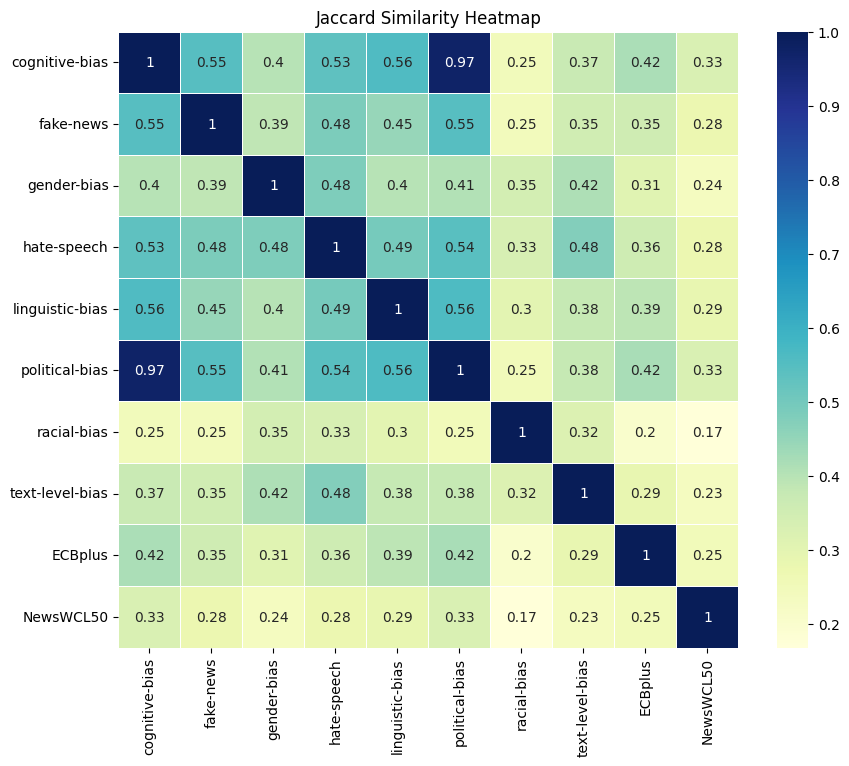

In [17]:

# Calculate Jaccard similarity for all pairs in processed_dataframes_dict
similarity_matrix = pd.DataFrame(index=processed_dataframes_dict.keys(), columns=processed_dataframes_dict.keys())

for key1, set1 in processed_dataframes_dict.items():
    for key2, set2 in processed_dataframes_dict.items():
            similarity_matrix.loc[key1, key2] = jaccard_similarity(set1, set2)

# Convert the dataframe values to numeric
similarity_matrix = similarity_matrix.apply(pd.to_numeric)

# Create a heatmap using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", linewidths=.5)
plt.title("Jaccard Similarity Heatmap")
plt.show()

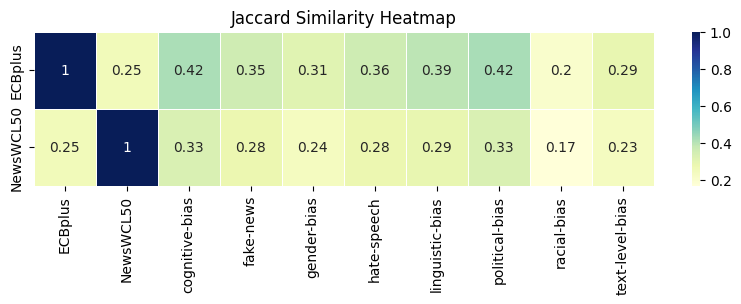

In [18]:
# Extract keys for rows and columns
rows = ['ECBplus', 'NewsWCL50']
columns = ['ECBplus', 'NewsWCL50']
columns.extend([key for key in processed_dataframes_dict if key not in rows])



# Calculate Jaccard similarity for specified pairs
similarity_matrix = pd.DataFrame(index=rows, columns=columns)

for row_key in rows:
    for col_key in columns:
        similarity_matrix.loc[row_key, col_key] = jaccard_similarity(
            processed_dataframes_dict[row_key], processed_dataframes_dict[col_key]
        )

# Convert the dataframe values to numeric
similarity_matrix = similarity_matrix.apply(pd.to_numeric)

# Create a heatmap using seaborn
plt.figure(figsize=(10, 2))
sns.heatmap(similarity_matrix, annot=True, cmap="YlGnBu", linewidths=.5, square=False)
plt.title("Jaccard Similarity Heatmap")
plt.show()

In [19]:
### Check average document size

In [20]:
# Calculate average length for each dataset
for dataset_name, dataset_data in dataframes_dict.items():
    try:
        string_list = dataset_data['text']
        average_length = sum(len(s) for s in string_list) / len(string_list)
        print(f"Average length of strings in {dataset_name}: {average_length}")

    except TypeError as e:
        print(f"Error in {dataset_name}: {e}")

Average length of strings in cognitive-bias: 233.0685998825949
Error in fake-news: object of type 'float' has no len()
Average length of strings in gender-bias: 128.2008380724334
Average length of strings in hate-speech: 270.87579694592534
Average length of strings in linguistic-bias: 283.94485896448947
Error in political-bias: object of type 'float' has no len()
Average length of strings in racial-bias: 96.61248467511238
Average length of strings in text-level-bias: 186.382457307607


In [21]:
mixed_political_cognitive= pd.concat([dataframes_dict["political-bias"], dataframes_dict["cognitive-bias"]])
mixed_political_cognitive.drop_duplicates(subset=["text"],inplace=True)
mixed_political_cognitive.drop(["id","dataset_id"],axis=1,inplace=True)
mixed_political_cognitive.columns=["text","label_bias"]

#Map labels to binary value
mixed_political_cognitive['label_bias'] = mixed_political_cognitive['label_bias'].map({'0': 0, 'False': 0, '1': 1, 'True': 1})
mixed_political_cognitive.dropna(inplace=True)

In [22]:
## Export text column only as text file
mixed_political_cognitive["text"].to_csv("dapt_political_cognitive_bias.txt", sep='\t', index=False)


In [23]:
# Still pending exporting this dataset and the linguistic one

In [24]:
mixed_political_cognitive.to_excel("dapt_political_cognitive_dataset.xlsx",index=False)

ModuleNotFoundError: No module named 'openpyxl'